# Projeto Final

### Preparo de dados

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd

# Caminho para o diretório principal dos dados
base_path = Path('./Dados_EEG/eegmmidb')


def tira_janelas(X, y, sub_processar, run_processar, base_path):
    if not base_path.is_dir():
        print(f"Erro: O diretório '{base_path}' não foi encontrado.")
        print(f"Diretório atual: '{os.getcwd()}'")
        return
    
    else:
        print(f"Iniciando processamento dos dados de: {base_path.resolve()}\n")

    # --- 3. LOOP PRINCIPAL PARA PROCESSAR OS ARQUIVOS ---
    for subject_id in sub_processar:
        for run_id in run_processar:
            
            s_id_str = f"{subject_id:03d}" # ex: 001
            r_id_str = f"{run_id:02d}"     # ex: 01

            ann_filename = f"SUB_{s_id_str}_ANN_{r_id_str}.csv"
            sig_filename = f"SUB_{s_id_str}_SIG_{r_id_str}.csv"

            ann_filepath = base_path / ann_filename
            sig_filepath = base_path / sig_filename

                # Verifica se ambos os arquivos (ANN e SIG) existem
            if ann_filepath.exists() and sig_filepath.exists():
                #print(f"Processando: Sujeito {s_id_str}, Run {r_id_str}")

                try:
                    # --- LEITURA DOS ARQUIVOS ---
                    colunas_ann = ['rotulo', 'duracao_s', 'tamanho_amostras', 'amostra_inicio', 'amostra_final']
                    
                    df_ann = pd.read_csv(ann_filepath, header=None, names=colunas_ann)

                    df_sig = pd.read_csv(sig_filepath, header=None)

                    # --- EXTRAÇÃO DOS SEGMENTOS E RÓTULOS ---
                    for index, row in df_ann.iterrows():
                        
                        rotulo = row['rotulo']
                        inicio = row['amostra_inicio']
                        fim = row['amostra_final']

                        inicio = int(inicio)-1 # python começa zero
                        fim = int(fim)

                        segmento_sinal = df_sig.iloc[inicio:fim].values

                        X.append(segmento_sinal)
                        if (rotulo==1 or rotulo==4):
                            y.append(0)
                        elif (rotulo==2 or rotulo==5):
                            y.append(1)
                        elif (rotulo==3 or rotulo==6):
                            y.append(2)

                except Exception as e:
                    print(f"  -> Erro ao processar o par de arquivos para S{s_id_str}/R{r_id_str}: {e}")
            else:
                # arquiv não encontrado
                print(f"Aviso: Par de arquivos para Sujeito {s_id_str}, Run {r_id_str} não encontrado. Pulando.")
                pass

    print("\n--- Processamento Concluído ---")
        
    # convt array NumPy
    y = np.array(y)

    print(f"Total de segmentos extraídos: {len(X)}")
    print(f"Total de rótulos extraídos: {len(y)}")
    print(f"Exemplo de um segmento (shape): {X[0].shape if X else 'N/A'}")
    print(f"Rótulos únicos encontrados: {np.unique(y) if y.size > 0 else 'N/A'}")

In [2]:
X_move = [] #segmento sinal
y_move = [] #rótulos

sub_move = range(1, 103) # 1 a 103
run_move = [1, 5, 9]    # 1 a 12

base_path = Path('./Dados_EEG/eegmmidb')

tira_janelas(X_move, y_move, sub_move, run_move, base_path)

Iniciando processamento dos dados de: C:\Users\eduar\TCC\TCC-EEG_Control\Programa_CNN\Dados_EEG\eegmmidb


--- Processamento Concluído ---
Total de segmentos extraídos: 9180
Total de rótulos extraídos: 9180
Exemplo de um segmento (shape): (672, 64)
Rótulos únicos encontrados: [0 1 2]


In [ ]:
X_imag = [] #segmento sinal
y_imag = [] #rótulos

sub_imag = range(1, 10) # 1 a 103
run_imag = [2, 6, 10]   # 1 a 12

base_path = Path('./Dados_EEG/eegmmidb')

tira_janelas(X_imag, y_imag, sub_imag, run_imag, base_path)

### Seleção Dados para utilizar

In [3]:
DADOS_X = X_move
DADOS_Y = y_move

# DADOS_X = X_move + X_imag
# DADOS_Y = y_move + y_imag

In [4]:
DADOS_X[0].shape, DADOS_X[5].shape, DADOS_X[10].shape

((672, 64), (656, 64), (672, 64))

In [5]:
def veri_tam_janelas (sinais):
    tamanhos_das_janelas = [janela.shape[0] for janela in sinais]

    print("--- Verificação dos Tamanhos das Janelas ---")
    print(f"Total de janelas extraídas: {len(tamanhos_das_janelas)}")

    print("\n--- Resumo do Tamanho dos Sinais ---")
    print(f"Tamanho Mínimo: {np.min(tamanhos_das_janelas)} amostras")
    print(f"Tamanho Máximo: {np.max(tamanhos_das_janelas)} amostras")


sinais = DADOS_X
veri_tam_janelas(sinais)

--- Verificação dos Tamanhos das Janelas ---
Total de janelas extraídas: 9180

--- Resumo do Tamanho dos Sinais ---
Tamanho Mínimo: 416 amostras
Tamanho Máximo: 672 amostras


#### Ajusta tamanho das Janelas

In [6]:
# Corte das janelas Maiores
def recorte_central(segmento, tamanho_max):
    """
    Aplica um recorte central a um segmento para que ele se ajuste 
    ao tamanho_maximo.
    """
    compr_atual = segmento.shape[0]
    
    if compr_atual <= tamanho_max: # se menor ta ok
        return segmento 
        
    excesso = compr_atual - tamanho_max
    corte_inicio = excesso // 2 # força divisão inteira
    indice_final = corte_inicio + tamanho_max
    janela_cortada = segmento[corte_inicio:indice_final, :]
    
    return janela_cortada

In [7]:
#Preenchendo janelas Menores
def preenche_janela(segmento, tamanho_min):
    """
    Adiciona zeros a um segmento para que ele se ajuste 
    ao tamanho_minimo.
    """
    CANAIS = 64
    compr_atual = segmento.shape[0]
    
    if compr_atual >= tamanho_min: # se maior ta ok
        return segmento 
        
    faltante = tamanho_min - compr_atual
    padding = np.zeros((faltante, CANAIS)) # adiciona zeros

    janela_aumentada = np.vstack([segmento, padding])
    
    return janela_aumentada

Aplicando Ajustes

In [8]:
TAMANHO = 640
SINAL_X_BRUTO = DADOS_X
X_ajustado = []

for segmento in SINAL_X_BRUTO:
    segmento_cortado = recorte_central(segmento, TAMANHO)
    segmento_completo = preenche_janela(segmento_cortado, TAMANHO)
    X_ajustado.append(segmento_completo)


DADOS_X = X_ajustado
veri_tam_janelas(DADOS_X)

--- Verificação dos Tamanhos das Janelas ---
Total de janelas extraídas: 9180

--- Resumo do Tamanho dos Sinais ---
Tamanho Mínimo: 640 amostras
Tamanho Máximo: 640 amostras


#### Data Augmentation (tvz use)

In [ ]:
# Parâmetro de ruído 
noise_factor = 0.01

# Parâmetro de escala
scale_factor = 0.1  

# Deslocar o sinal no tempo
def shift_signal(data, maDADOS_X_shift):
    shift = np.random.randint(-maDADOS_X_shift, maDADOS_X_shift)
    return np.roll(data, shift, aDADOS_Xis=0)

shift_maDADOS_X = 20  # Máximo deslocamento

from scipy.ndimage import gaussian_filter1d

# jitter, escalonamento, deslocamento e suavização
X_noise = DADOS_X + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=DADOS_X.shape)
X_aug = X_noise * (1 + scale_factor * np.random.uniform(-1, 1, size=DADOS_X.shape))
X_aug = gaussian_filter1d(DADOS_X, sigma=2, aDADOS_Xis=1) 
X_aug = np.array([shift_signal(dado, shift_maDADOS_X) for dado in X_aug])

# Filtra rotulos a aumentar
# X_menos = DADOS_X[DADOS_Y != 0]
# Y_menos = DADOS_Y[DADOS_Y != 0]

# # data augmentation para equilibrar rotulos
# X_noise = X_menos + noise_factor * np.random.normal(loc=0.0, scale=1.0, size=X_menos.shape)
# X_aug = X_noise * (1 + scale_factor * np.random.uniform(-1, 1, size=X_noise.shape))
# X_aug = gaussian_filter1d(X_aug, sigma=2, aDADOS_Xis=1)
# X_aug = np.array([shift_signal(dado, shift_maDADOS_X) for dado in X_aug])


X_aug = np.concatenate([DADOS_X, X_aug], aDADOS_Xis=0)
y_aug = np.concatenate([DADOS_Y, DADOS_Y], aDADOS_Xis=0)

print(f"Forma dos dados: {X_aug.shape}")
print(f"Forma dos rótulos: {y_aug.shape}")

# DADOS_X = X_aug
# DADOS_Y = y_aug

### Separação Dados Treino e Validação

In [37]:
from sklearn.model_selection import train_test_split

DADOS_X = np.array(DADOS_X, dtype=np.float32)
DADOS_Y = np.array(DADOS_Y, dtype=np.int64)


X_train, X_test, y_train, y_test = train_test_split(DADOS_X, DADOS_Y, 
                                                    test_size=0.20, 
                                                    random_state=0,
                                                    stratify= DADOS_Y   # GARANTE MESMA PROPORÇÃO DE CLASSES
                                                    )  
print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

7344 7344
1836 1836


In [38]:
# --- PASSO 5: VERIFICAÇÃO FINAL ---
print("\n--- Verificação Pós-Divisão ---")
print(f"Tipo de X_train: {type(X_train)}") # <<< Agora será <class 'numpy.ndarray'>
print(f"Shape de X_train: {X_train.shape}") # <<< AGORA O .SHAPE VAI FUNCIONAR!
print(f"Shape de y_train: {y_train.shape}")


--- Verificação Pós-Divisão ---
Tipo de X_train: <class 'numpy.ndarray'>
Shape de X_train: (7344, 640, 64)
Shape de y_train: (7344,)


In [39]:
# NORMALIZAÇÃO 
from sklearn.preprocessing import StandardScaler

print("Normalizando os dados (fit APENAS no treino)...")
scaler = StandardScaler()

# Remodelar para 2D para o scaler
X_train_reshaped = X_train.reshape(-1, X_train.shape[-1])
X_test_reshaped = X_test.reshape(-1, X_test.shape[-1])

# Ajustar o scaler APENAS nos dados de treino
scaler.fit(X_train_reshaped)

# Transformar ambos os conjuntos com o scaler já ajustado
X_train_scaled_reshaped = scaler.transform(X_train_reshaped)
X_test_scaled_reshaped = scaler.transform(X_test_reshaped)

# Remodelar de volta para 3D para a rede neural
X_train_scaled = X_train_scaled_reshaped.reshape(X_train.shape)
X_test_scaled = X_test_scaled_reshaped.reshape(X_test.shape)

print("Dados normalizados com sucesso!")

Normalizando os dados (fit APENAS no treino)...
Dados normalizados com sucesso!


In [40]:
import pickle

with open('dados_EEG.pkl', mode='wb') as f:
    pickle.dump([X_train, y_train, X_test, y_test], f)

### Importando Dados

In [55]:
with open('dados_EEG.pkl', mode='rb') as f:
    X_train, y_train, X_test, y_test = pickle.load(f)

print(len(X_train), len(y_train))
print(len(X_test), len(y_test))

7344 7344
1836 1836


# Arquitetura 1D CNN com Keras

In [42]:
import tensorflow as tf
from keras.models import Sequential
from keras.layers import Conv1D, MaxPooling1D, Flatten, Dense, BatchNormalization, Input, Dropout
from keras.callbacks import EarlyStopping, ReduceLROnPlateau
from keras.optimizers import Adam

### Modelo Próprio

In [17]:
# Definindo o modelo
model = Sequential()
qnt_canais = 64
# Camada de entrada com Input(shape)
model.add(Input(shape=(TAMANHO, qnt_canais)))

# # Adicionando a camada de convolução 1D
# model.add(Conv1D(filters=64, kernel_size=9, activation='relu'))

# Convolução 1D
model.add(Conv1D(filters=64, kernel_size=6, activation='relu'))

# Dropout 50%
model.add(Dropout(0.3))

# Convolução 1D
model.add(Conv1D(filters=64, kernel_size=3, activation='relu'))

# Adicionando uma camada de pooling 1D
model.add(MaxPooling1D(pool_size=2))

# Flatten e Dense 
model.add(Flatten())
model.add(Dense(80, activation='relu'))

# Dropout 50%
model.add(Dropout(0.5))
model.add(Dense(3, activation='softmax'))  # Para classificação de múltiplas classes

# Compilando o modelo
model.compile(optimizer='adam', 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

# Resumo do modelo
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 635, 64)        │        24,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 635, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 633, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 316, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20224)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 80)             │     1,618,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 80)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           243 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,655,235 (6.31 MB)

 Trainable params: 1,655,235 (6.31 MB)

 Non-trainable params: 0 (0.00 B)

### DeepConvNet adp

In [56]:
from keras.models import Sequential
from keras.layers import Input, Conv1D, Dense, Dropout, BatchNormalization, MaxPooling1D, Flatten
from keras.optimizers import Adam

def build_deepconvnet(timesteps, n_features, n_classes):
    """
    Constrói um modelo 1D CNN inspirado na arquitetura DeepConvNet para classificação de EEG.
    """
    model = Sequential()
    
    # --- CAMADA DE ENTRADA ---
    model.add(Input(shape=(timesteps, n_features)))
    
    # --- BLOCO 1: CONVOLUÇÃO TEMPORAL ---
    # Aprende filtros temporais
    model.add(Conv1D(filters=25, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))
    
    # --- BLOCO 2: CONVOLUÇÕES PROFUNDAS ---
    model.add(Conv1D(filters=50, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))

    model.add(Conv1D(filters=100, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))

    model.add(Conv1D(filters=200, kernel_size=10, activation='elu', padding='same'))
    model.add(BatchNormalization())
    model.add(MaxPooling1D(pool_size=3, strides=3))
    
    # --- BLOCO DE CLASSIFICAÇÃO ---
    model.add(Flatten())
    model.add(Dense(100, activation='elu'))
    model.add(Dropout(0.5))
    model.add(Dense(n_classes, activation='softmax')) # Camada de saída
    
    return model

# --- Exemplo de como usar ---
# Seus parâmetros
TIMESTEPS = 640  # O comprimento da sua janela padronizada
N_FEATURES = 64   # Número de canais de EEG
N_CLASSES = 3     # Número de classes (0, 1, 2)

# Constrói o modelo
model = build_deepconvnet(TIMESTEPS, N_FEATURES, N_CLASSES)

# Compila o modelo (use uma taxa de aprendizado menor para começar)
optimizer = Adam(learning_rate=0.0005)
model.compile(optimizer=optimizer, 
              loss='sparse_categorical_crossentropy', 
              metrics=['accuracy'])

# Mostra o resumo do modelo
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_22 (Conv1D)              │ (None, 640, 25)        │        16,025 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 640, 25)        │           100 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_21 (MaxPooling1D) │ (None, 213, 25)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_23 (Conv1D)              │ (None, 213, 50)        │        12,550 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 213, 50)        │           200 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_22 (MaxPooling1D) │ (None, 71, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_24 (Conv1D)              │ (None, 71, 100)        │        50,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_22          │ (None, 71, 100)        │           400 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_23 (MaxPooling1D) │ (None, 23, 100)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_25 (Conv1D)              │ (None, 23, 200)        │       200,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_23          │ (None, 23, 200)        │           800 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_24 (MaxPooling1D) │ (None, 7, 200)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 1400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 100)            │       140,100 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 3)              │           303 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,778 (1.61 MB)

 Trainable params: 420,028 (1.60 MB)

 Non-trainable params: 750 (2.93 KB)

### Treinando

In [57]:
from sklearn.utils import class_weight

# Calcula os pesos das classes com base no y_train
class_weights = class_weight.compute_class_weight('balanced',
                                                 classes=np.unique(y_train),
                                                 y=y_train)
# Converte para um dicionário Keras entende
class_weights_dict = dict(enumerate(class_weights))

print("Pesos calculados para as classes:", class_weights_dict)

Pesos calculados para as classes: {0: np.float64(0.6666666666666666), 1: np.float64(1.329712112982075), 2: np.float64(1.3369743309666848)}


In [58]:
# Define os callbacks
early_stopping = EarlyStopping(monitor='val_loss',
                               patience=15, 
                               restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', 
                              factor=0.5, 
                              patience=7, 
                              min_lr=1e-6)

# Treina modelo
model.fit(X_train, y_train, 
          epochs=40, 
          batch_size=32, 
          validation_data=(X_test, y_test), 
          callbacks=[early_stopping, reduce_lr], # callbacks
          class_weight=class_weights_dict)  


print(f"Tamanho do conjunto de treino: {X_train.shape[0]} amostras")
print(f"Tamanho do conjunto de teste: {X_test.shape[0]} amostras")

Epoch 1/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - accuracy: 0.4248 - loss: 1.6904 - val_accuracy: 0.5664 - val_loss: 0.9514 - learning_rate: 5.0000e-04
Epoch 2/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.5800 - loss: 0.9860 - val_accuracy: 0.6280 - val_loss: 0.8520 - learning_rate: 5.0000e-04
Epoch 3/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.6309 - loss: 0.8397 - val_accuracy: 0.6563 - val_loss: 0.8092 - learning_rate: 5.0000e-04
Epoch 4/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 40ms/step - accuracy: 0.6894 - loss: 0.7353 - val_accuracy: 0.6580 - val_loss: 0.8011 - learning_rate: 5.0000e-04
Epoch 5/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.7385 - loss: 0.6403 - val_accuracy: 0.6830 - val_loss: 0.7873 - learning_rate: 5.0000e-04
Epoch 6/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 9s 38ms/step - accuracy: 0.7524 - loss: 0.5889 - val_accuracy: 0.7320 - val_loss: 0.6663 - learning_rate: 5.0000e-04
Epoch 7/40
230/230 ━━━━━━━━━━━━━━━━━━━━ 10s 43ms/step - 

accuracy: 0.4434 - loss: 1.2756 - val_accuracy: 0.4200 - val_loss: 1.3564 - learning_rate: 9.0000e-05

In [46]:
caminho_pesos = 

# Salvar os pesos do modelo
model.save_weights(caminho_pesos)

print(f"Pesos do modelo foram salvos em: {caminho_pesos}")

SyntaxError: invalid syntax (3280306386.py, line 1)

### Matriz Confusão

58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7137 - loss: 0.6827
Acurácia: 0.7320261597633362
58/58 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step
[[725  79 114]
 [ 98 307  55]
 [ 96  50 312]]


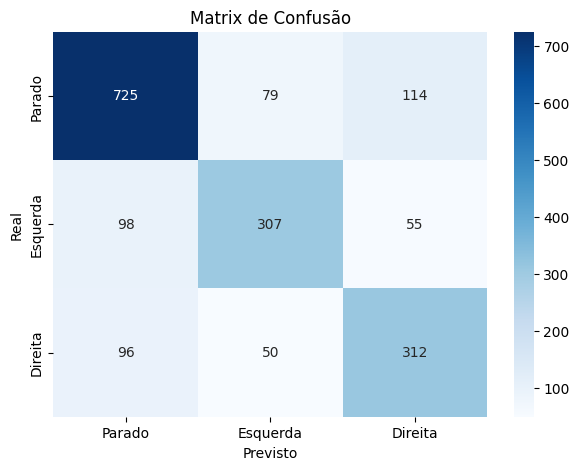

In [59]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Avaliar o modelo
loss, accuracy = model.evaluate(X_test, y_test)
print(f'Acurácia: {accuracy}')
# Fazer previsões
predictions = model.predict(X_test)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = y_test if len(y_test.shape) == 1 else np.argmax(y_test, axis=1)

# Calcula matriz de confusão
conf_matrix = confusion_matrix(true_classes, predicted_classes)
print(conf_matrix)

class_names = ['Parado', 'Esquerda', 'Direita']
# plot matriz de confusão
plt.figure(figsize=(7, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Previsto')
plt.ylabel('Real')
plt.title('Matrix de Confusão')
plt.savefig('confusion_matrix_1Dcnn.png')
plt.show()